# İlaç Kullanım Trendi Analizi

TRSM veri setindeki (`trsm.db`) ilaç kullanım kayıtlarının yıllara göre dağılımını gösterir. Kaynak: alt proje 1'in ürettiği yapılandırılmış veritabanı (`ilac_kullanimi`, `ziyaret` tabloları).

## 1. Veri Yükleme ve Güven Filtresi

Bulanık eşleştirme güven skoru (`eslesme_guveni`) düşük olan kayıtlar trend grafiklerini çarpıtabileceğinden bir eşik altında filtrelenir. `GUVEN_ESIGI` değeri değiştirilerek farklı eşiklerin sonucu nasıl etkilediği gösterilebilir.

In [1]:
import sqlite3
import pandas as pd

DB_PATH = "../trsm.db"
GUVEN_ESIGI = 90

conn = sqlite3.connect(DB_PATH)
toplam_kayit = conn.execute("SELECT COUNT(*) FROM ilac_kullanimi").fetchone()[0]

query = """
    SELECT ik.ilac_adi_normalize, ik.eslesme_guveni, z.tarih
    FROM ilac_kullanimi ik
    JOIN ziyaret z ON z.id = ik.ziyaret_id
    WHERE ik.eslesme_guveni >= ?
"""
df = pd.read_sql(query, conn, params=(GUVEN_ESIGI,))
conn.close()

dusuk_guvenli_sayisi = toplam_kayit - len(df)
print(f"Veritabanındaki toplam ilaç kaydı: {toplam_kayit}")
print(f"Güven eşiği (>= {GUVEN_ESIGI}) altında filtrelenen kayıt: {dusuk_guvenli_sayisi}")
print(f"Analize dahil edilebilecek kayıt (güven filtresi sonrası): {len(df)}")
df.head()

Veritabanındaki toplam ilaç kaydı: 18937
Güven eşiği (>= 90) altında filtrelenen kayıt: 2650
Analize dahil edilebilecek kayıt (güven filtresi sonrası): 16287


,ilac_adi_normalize,eslesme_guveni,tarih
0,Abilify Maintena,100.0,2024-08-09
1,Abilify Maintena,100.0,2025-06-17
2,Akineton,100.0,2025-06-17
3,Cedrina,100.0,2025-06-17
4,Lithium,100.0,2025-06-17


## 2. Tarih / Yıl İşleme

`ziyaret.tarih` alanı zaten ISO formatında (`YYYY-MM-DD`) normalize edilmiş (alt proje 1). Tarihi olmayan kayıtlar yıllık trendden hariç tutulur ve sayısı raporlanır.

In [2]:
tarihsiz_sayisi = df["tarih"].isna().sum()
print(f"Tarihi olmayan ilaç kaydı sayısı: {tarihsiz_sayisi} ({tarihsiz_sayisi/len(df):.1%})")

df = df.dropna(subset=["tarih"]).copy()
df["yil"] = df["tarih"].str[:4].astype(int)
print(f"Analize dahil edilen kayıt: {len(df)}")
print(f"Kapsanan yıl aralığı: {df['yil'].min()} - {df['yil'].max()}")

Tarihi olmayan ilaç kaydı sayısı: 7499 (46.0%)
Analize dahil edilen kayıt: 8788
Kapsanan yıl aralığı: 2005 - 2025


## 3. Yıl × İlaç Gruplaması ve En Sık 10 İlaç

42 ilacın tamamını tek grafikte göstermek okunabilirliği bozacağından, tüm zaman aralığında en sık geçen ilk 10 ilaç seçilir.

In [3]:
yillik_sayim = df.groupby(["yil", "ilac_adi_normalize"]).size().reset_index(name="sayi")

en_sik_10 = df["ilac_adi_normalize"].value_counts().head(10).index.tolist()
print("En sık kullanılan 10 ilaç:")
for i, ilac in enumerate(en_sik_10, 1):
    print(f"{i}. {ilac}")

En sık kullanılan 10 ilaç:
1. Depakin
2. Akineton
3. Lithium
4. Xeplion
5. Abilify Maintena
6. Risperdal
7. Clonex
8. Rexapin
9. Gyrex
10. Cedrina


## 4. Trend Grafiği ve Pivot Tablo

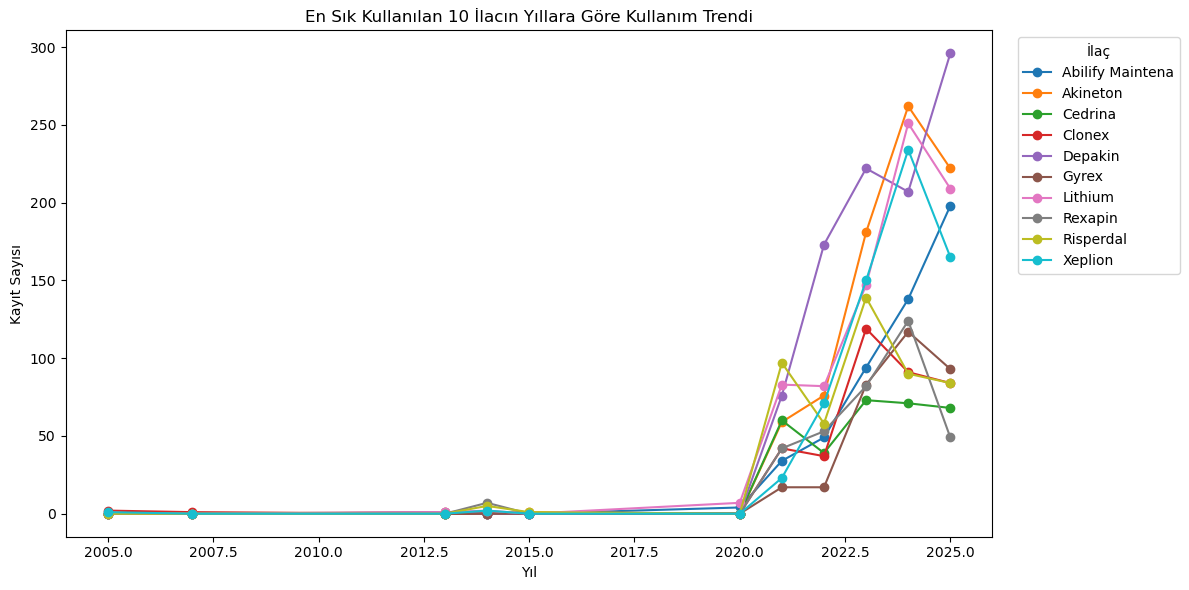

ilac_adi_normalize,Abilify Maintena,Akineton,Cedrina,Clonex,Depakin,Gyrex,Lithium,Rexapin,Risperdal,Xeplion
yil,,,,,,,,,,
2005,0.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,1.0
2007,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2013,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
2014,0.0,1.0,0.0,0.0,0.0,0.0,2.0,7.0,5.0,2.0
2015,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2020,4.0,0.0,0.0,0.0,0.0,0.0,7.0,0.0,0.0,0.0
2021,34.0,59.0,60.0,42.0,76.0,17.0,83.0,42.0,97.0,23.0
2022,49.0,76.0,39.0,37.0,173.0,17.0,82.0,53.0,58.0,71.0
2023,94.0,181.0,73.0,119.0,222.0,83.0,147.0,82.0,139.0,150.0


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

pivot = (
    yillik_sayim[yillik_sayim["ilac_adi_normalize"].isin(en_sik_10)]
    .pivot(index="yil", columns="ilac_adi_normalize", values="sayi")
    .fillna(0)
)

fig, ax = plt.subplots(figsize=(12, 6))
pivot.plot(ax=ax, marker="o")
ax.set_xlabel("Yıl")
ax.set_ylabel("Kayıt Sayısı")
ax.set_title("En Sık Kullanılan 10 İlacın Yıllara Göre Kullanım Trendi")
ax.legend(title="İlaç", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig("ilac_kullanim_trendi.png", dpi=150)
plt.show()

pivot

## 5. Özet

In [5]:
print("=== Özet ===")
print(f"Veritabanındaki toplam ilaç kaydı: {toplam_kayit}")
print(f"Güven eşiği (>= {GUVEN_ESIGI}) altında filtrelenen kayıt: {dusuk_guvenli_sayisi}")
print(f"Tarihsiz kayıt (analiz dışı bırakıldı): {tarihsiz_sayisi}")
print(f"Analize dahil edilen kayıt: {len(df)}")
print(f"Kapsanan yıl aralığı: {df['yil'].min()} - {df['yil'].max()}")

=== Özet ===
Veritabanındaki toplam ilaç kaydı: 18937
Güven eşiği (>= 90) altında filtrelenen kayıt: 2650
Tarihsiz kayıt (analiz dışı bırakıldı): 7499
Analize dahil edilen kayıt: 8788
Kapsanan yıl aralığı: 2005 - 2025


## 6. Veri Kalitesi Notu: 2021 Öncesi Tarihler

Yukarıdaki analize dahil edilen kayıtların **%99.2'si 2021-2025** aralığında, ancak **272 kayıt (%0.65), 24 farklı hasta dosyasında, 2021 öncesi** bir tarih taşıyor (en erken: 1994). Bu kayıtlar kaynak OCR verisinde incelendi ve üç ayrı kök neden tespit edildi:

1. **Gerçek erken ziyaretler** olabilir (örn. bir hastanın 2015'te başlayan tedavi geçmişi) — bunlar analize dahil kalmalı.
2. **OCR yanlış okuması**: örn. bir dosyada tarih `2014-04-10` olarak çıkmış, ama aynı sayfadaki serbest metinde `25.11.2024`/`10.01.2025` gibi tarihlere referans var ve sayfa genel olarak ağır OCR bozulması içeriyor — bu kaydın gerçekte 2024 olması muhtemel.
3. **Form şablonu karışıklığı**: bazı dosyalarda "Tarih" kolonu, ziyaret tarihi yerine bir **hasta öykü/geçmiş formu**ndaki olay tarihini (örn. "hastalık başlangıcı", "askerlik hizmeti") içeriyor; forward-fill mantığı bunu sonraki satırlara yanlışlıkla ziyaret tarihi gibi yaymış olabilir. Bir dosyada ise `Tarih=16.06.1994` değeri aslında hastanın doğum tarihi + boy/kilo verisiyle (`Boy: 172`, `Kilo: 68.4`) eşleşiyor — ziyaret tarihi değil.

**Önemli:** Bu, bu notebook'un veya alt proje 1'in kodundan kaynaklanmıyor — `tarih[:4]` ile yıl çıkarımı, veritabanındaki tarih metnini doğru şekilde işliyor. Kök neden, kaynak OCR dönüşümünde (bu notebook'un kapsamı dışında, önceden tamamlanmış bir adım) bazı sayfaların çok bozuk olması ve/veya farklı form şablonlarının aynı "Tarih" kolonuna eşlenmesi. Tez metodoloji/sınırlılıklar bölümünde bu durumun belirtilmesi ve mümkünse etkilenen 24 dosyanın kaynak PDF'lerden elle kontrol edilmesi önerilir.

In [6]:
conn = sqlite3.connect(DB_PATH)
anomali_sorgu = """
    SELECT h.dosya_adi, COUNT(*) as kayit_sayisi, MIN(z.tarih) as min_tarih, MAX(z.tarih) as max_tarih
    FROM ziyaret z
    JOIN hasta h ON h.id = z.hasta_id
    WHERE z.tarih IS NOT NULL AND substr(z.tarih, 1, 4) < '2021'
    GROUP BY h.dosya_adi
    ORDER BY kayit_sayisi DESC
"""
anomali_df = pd.read_sql(anomali_sorgu, conn)
conn.close()

print(f"Etkilenen benzersiz dosya sayısı: {len(anomali_df)}")
print(f"Toplam etkilenen ziyaret sayısı: {anomali_df['kayit_sayisi'].sum()}")
anomali_df

Etkilenen benzersiz dosya sayısı: 24
Toplam etkilenen ziyaret sayısı: 272


,dosya_adi,kayit_sayisi,min_tarih,max_tarih
0,Murat Özoğur.pdf,71,2019-03-25,2019-03-25
1,Şevket Emre özgür .pdf,65,2015-03-19,2015-05-16
2,Reyyhan DURAN.pdf,34,2020-09-26,2020-10-13
3,Meltem Gül.pdf,26,2014-04-10,2014-04-10
4,Meltem Cinan.pdf,16,2019-06-19,2019-06-19
5,Ayşelal Türkü Avcı 2.pdf,13,2019-03-29,2019-03-30
6,Bahattin Hep.pdf,8,2020-12-22,2020-12-22
7,Elif Büşra Yasak.pdf,7,2020-11-29,2020-11-29
8,Funda Yılmaz.pdf,5,2020-07-09,2020-09-03
9,Ferdi Bozoğlan 2.pdf,5,2007-09-09,2007-09-09
